# XGBoost + temporal context + cascade water values

Steps 3 and 4 of the improvement plan, built on the best model so far (`xgboost_constraints.ipynb`, 2022 micro AUC **0.9792**
under the honest protocol). The error analysis showed a third of the remaining error sits within two hours of a start or
stop, and that smoothing the predictions afterwards makes things worse, so the context has to go into the features.

**Temporal context** (per plant, from its margin `price − end-of-week water value`): centred rolling mean / max / min over
3, 6 and 12 h; number of positive-margin hours in the day; rank of the margin within the day; and run lengths, i.e. how many
consecutive hours the margin has been positive (negative) up to *t* and how many it stays positive (negative) from *t* on.
The run lengths are the natural inputs for a start/stop decision with a 94 EUR start cost.

**Cascade** (per plant that discharges into another reservoir): the downstream reservoir's water value at case start and
end, the upstream-minus-downstream water-value difference, and price minus that difference. Water used at Tokke lands in
Bandak and is used again at Hogga, so the real opportunity cost of running Tokke is the difference, not Vinjevatn's value.

Three honest fits are run so the gain can be attributed: context only, cascade only, both.

### Shared code

Data loading, feature construction and the honest validation protocol. The same code is repeated at the top of every notebook so each one runs on its own.

In [ ]:
from pathlib import Path
from scipy.ndimage import uniform_filter1d, maximum_filter1d, minimum_filter1d
from sklearn.metrics import roc_auc_score
import json
import numpy as np
import pandas as pd
import re
import time
import xgboost as xgb

# ---- formerly src/train_xgb_baseline.py ----
# XGBoost baseline for the SINTEF unit-commitment task.
#
# Script version of xgboost_baseline.ipynb so it can run headless on the GPU desktop.
#
# Validation protocol: rounds are chosen by early stopping on 2021 (training on cases before 2021);
# the reported score is then from a model trained on cases before 2022 and scored on 2022, so the
# reported year never influences a modelling decision. A one-week gap keeps overlapping cases apart.
#
#     py train_xgb_baseline.py --device cuda          # GPU
#     python train_xgb_baseline.py --device cpu       # laptop
#
# Outputs (in --out, default ./results):
#     submission_xgb_baseline.csv   Kaggle submission (test cases 2023-2024)
#     val_pred_2022.npy             hold-out probabilities, shape (365*168, 14)
#     metrics.json                  hold-out micro AUC, per-unit AUC, best iteration, timings
#     feature_importance.csv        gain per feature (summed over the 14 boosters)

H = 168
SEED = 42

def load(data_dir):
    data_dir = Path(data_dir)
    uc = pd.read_csv(
        data_dir / "Unit_commitment_decisions.csv", parse_dates=["starttime"]
    )
    price = (
        pd.read_csv(
            data_dir / "Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"]
        )
        .set_index("date")["Day-ahead price (EUR/MWh)"]
        .resample("h")
        .mean()
    )
    inflow = pd.read_csv(
        data_dir / "Historical_inflow_1958_2025.csv", parse_dates=["date"]
    ).set_index("date")
    inflow = inflow[inflow.index >= "2014-12-01"].resample("h").mean()
    volume = pd.read_csv(
        data_dir / "Historical_volume_2015_2024.csv", parse_dates=["date"]
    ).set_index("date")
    water_value = pd.read_csv(
        data_dir / "Synthetic_water_value_2015_2024.csv", parse_dates=["date"]
    ).set_index("date")
    return uc, price, inflow, volume, water_value

class FeatureBuilder:
    def __init__(self, price, inflow, volume, water_value):
        self.price, self.inflow, self.volume, self.wv = (
            price,
            inflow,
            volume,
            water_value,
        )

    @staticmethod
    def window(hourly_df, starts, horizon=H):
        idx = hourly_df.index.get_indexer(starts)
        assert (idx >= 0).all(), (
            "some case start times are missing from the hourly series"
        )
        pos = idx[:, None] + np.arange(horizon)[None, :]
        return hourly_df.to_numpy(dtype=np.float32)[pos]

    def __call__(self, starts):
        starts = pd.DatetimeIndex(starts)
        if starts.tz is None:
            starts = starts.tz_localize("UTC")
        n = len(starts)
        P = self.window(self.price.to_frame(), starts)[:, :, 0]
        I = self.window(self.inflow, starts)
        V = self.volume.reindex(starts).to_numpy(dtype=np.float32)
        W = self.wv.reindex(starts).to_numpy(dtype=np.float32)
        W_end = self.wv.reindex(starts + pd.Timedelta(days=7)).to_numpy(
            dtype=np.float32
        )
        hours = pd.DatetimeIndex(
            (
                starts.values[:, None] + np.arange(H)[None, :] * np.timedelta64(1, "h")
            ).ravel()
        )
        rep = lambda a: np.repeat(a, H)

        f = pd.DataFrame(
            {
                "t": np.tile(np.arange(H), n),
                "hour": hours.hour,
                "dow": hours.dayofweek,
                "month": hours.month,
                "doy": hours.dayofyear,
                "price": P.ravel(),
                "price_week_mean": rep(P.mean(1)),
                "price_week_std": rep(P.std(1)),
                "price_week_min": rep(P.min(1)),
                "price_week_max": rep(P.max(1)),
            }
        )
        f["price_rel"] = f["price"] - f["price_week_mean"]
        f["price_rank"] = (P.argsort(1).argsort(1) / (H - 1)).ravel()
        f["price_day_mean"] = np.repeat(P.reshape(n, 7, 24).mean(2), 24, axis=1).ravel()
        f["price_prev"] = np.concatenate([P[:, :1], P[:, :-1]], axis=1).ravel()   # edge-padded, no wrap
        f["price_next"] = np.concatenate([P[:, 1:], P[:, -1:]], axis=1).ravel()
        for j, c in enumerate(self.inflow.columns):
            f[f"inflow_{c}"] = I[:, :, j].ravel()
        f["inflow_total"] = I.sum(2).ravel()
        for j, c in enumerate(self.volume.columns):
            f[f"vol_{c}"] = rep(V[:, j])
        for j, c in enumerate(self.wv.columns):
            f[f"wv_{c}"] = rep(W[:, j])
        for j, c in enumerate(self.wv.columns):
            f[f"wv_end_{c}"] = rep(W_end[:, j])
        return f

def split_masks(starts, val_year, gap_days=7):
    """Case-level masks. train: cases whose whole week ends before val_year (so no hour is shared with the
    validation cases); val: cases starting in val_year. Returned per case, use np.repeat(mask, H) for rows."""
    starts = pd.DatetimeIndex(starts)
    val_start = pd.Timestamp(f"{val_year}-01-01")
    train = np.asarray(starts < val_start - pd.Timedelta(days=gap_days - 1))
    val = np.asarray(starts.year == val_year)
    return train, val

def honest_fit(X, Y, starts, params, tune_year=2021, report_year=2022, device="cuda", verbose=False, max_rounds=3000):
    """Two-stage validation so the reported year is never used to make a modelling decision.

    stage 1: train on cases before tune_year, early-stop on tune_year  -> number of rounds
    stage 2: train on cases before report_year with that many rounds   -> score on report_year
    Returns a dict with n_rounds, tune_auc, report_auc, per-unit AUC, the stage-2 model and its predictions.
    """
    common = dict(tree_method="hist", device=device, random_state=SEED, **params)
    tr1, va1 = (np.repeat(m, H) for m in split_masks(starts, tune_year))
    m1 = xgb.XGBClassifier(n_estimators=max_rounds, eval_metric="auc", early_stopping_rounds=100, **common)
    m1.fit(X[tr1], Y[tr1], eval_set=[(X[va1], Y[va1])], verbose=verbose)
    n_rounds = int(m1.best_iteration) + 1
    tune_auc = roc_auc_score(Y[va1], m1.predict_proba(X[va1]), average="micro")

    tr2, va2 = (np.repeat(m, H) for m in split_masks(starts, report_year))
    m2 = xgb.XGBClassifier(n_estimators=n_rounds, **common).fit(X[tr2], Y[tr2])
    pred = m2.predict_proba(X[va2])
    report_auc = roc_auc_score(Y[va2], pred, average="micro")   # identical to kaggle_metric.score
    per_unit = [roc_auc_score(Y[va2][:, j], pred[:, j]) for j in range(Y.shape[1])]
    return dict(n_rounds=n_rounds, tune_auc=float(tune_auc), report_auc=float(report_auc),
                per_unit=per_unit, model=m2, pred=pred, val_mask=va2)

# ---- formerly src/features_margin.py ----
# Price-minus-water-value features (see xgboost_price_minus_wv.ipynb).
# plant -> reservoir directly upstream, from the connections in data/extended/Tokke_Vinje_topology.yaml
UPSTREAM = {
    "Hogga": "Bandak", "Tokke": "Vinjevatn", "Lio": "Byrtevatn", "Byrte": "Botnedalsvatn",
    "Vinje": "Vaamarvatn", "Haukeli": "Vatjern", "Songa": "Songavatn", "Kjela": "Foersvatn",
    "Vesle Kjela": "Kjelavatn",
}

def add_margin_features(f):
    f = f.copy()
    for plant, res in UPSTREAM.items():
        f[f"margin_{plant}"] = f["price"] - f[f"wv_{res}"]
        f[f"margin_end_{plant}"] = f["price"] - f[f"wv_end_{res}"]
        f[f"margin_end_wk_{plant}"] = f["price_week_mean"] - f[f"wv_end_{res}"]
    return f

# ---- formerly src/features_constraints.py ----
# Environmental-constraint features from data/extended (see xgboost_constraints.ipynb).
#
# Hourly minimum river flows (6 rivers) and minimum reservoir volumes (3 reservoirs), plus the distance between the
# reservoir's volume at case start and its minimum. All are inputs the optimiser receives for the case week.

H = 168

def load_constraints(data_dir="data/extended"):
    data_dir = Path(data_dir)
    minflow = pd.read_csv(data_dir / "Constraint_min_flow.csv", parse_dates=["date"]).set_index("date").resample("h").mean()
    minvol = pd.read_csv(data_dir / "Constraint_min_volume.csv", parse_dates=["date"]).set_index("date").resample("h").mean()
    return minflow, minvol

class ConstraintFeatures:
    def __init__(self, minflow, minvol, volume):
        self.minflow, self.minvol, self.volume = minflow, minvol, volume

    @staticmethod
    def window(hourly_df, starts):
        idx = hourly_df.index.get_indexer(starts)
        assert (idx >= 0).all(), "case start missing from constraint series"
        return hourly_df.to_numpy(dtype=np.float32)[idx[:, None] + np.arange(H)[None, :]]   # (n, H, cols)

    def __call__(self, starts):
        starts = pd.DatetimeIndex(starts)
        if starts.tz is None:
            starts = starts.tz_localize("UTC")
        n = len(starts)
        rep = lambda a: np.repeat(a, H)
        MF = self.window(self.minflow, starts)
        MV = self.window(self.minvol, starts)
        V = self.volume.reindex(starts)

        f = {}
        for j, river in enumerate(self.minflow.columns):
            f[f"minflow_{river}"] = MF[:, :, j].ravel()                 # requirement at hour t
            f[f"minflow_{river}_wkmax"] = rep(MF[:, :, j].max(1))       # tightest requirement during the week
        for j, res in enumerate(self.minvol.columns):
            v0 = V[res].to_numpy(dtype=np.float32)
            f[f"minvol_{res}"] = MV[:, :, j].ravel()
            f[f"volgap_{res}"] = rep(v0) - MV[:, :, j].ravel()           # volume at case start minus minimum at hour t
            f[f"volgap_{res}_wkmin"] = rep(v0 - MV[:, :, j].max(1))      # worst-case slack during the week
        return pd.DataFrame(f)

def add_constraint_features(f, starts, constraint_features):
    extra = constraint_features(starts)
    assert len(extra) == len(f)
    return pd.concat([f.reset_index(drop=True), extra], axis=1)

# ---- formerly src/features_context.py ----
# Temporal-context and cascade features on top of the margin features (see xgboost_context.ipynb).
#
# Context (per plant, from margin_end_<plant> = price - end-of-week water value of the upstream reservoir):
#   centred rolling mean / max / min over 3, 6 and 12 hours, number of positive-margin hours in the same day,
#   rank of the margin within the day, and run lengths: consecutive positive (negative) margin hours up to t and from t on.
# Cascade (per plant with a downstream reservoir): the downstream reservoir's water value at case start and end,
#   the upstream-minus-downstream difference, and price minus that difference ("cascade margin").

H = 168
# plant -> reservoir the plant discharges into (plant -> reservoir connections in Tokke_Vinje_topology.yaml)
DOWNSTREAM = {"Tokke": "Bandak", "Vinje": "Vinjevatn", "Haukeli": "Vinjevatn", "Byrte": "Byrtevatn",
              "Kjela": "Hyljelihyl", "Vesle Kjela": "Foersvatn", "Songa": "Totak"}   # Lio -> river, Hogga -> outlet
WINDOWS = (3, 6, 12)

def _run_lengths(pos):
    """pos: bool (n, H). Returns consecutive-True counts ending at t and starting at t."""
    n = pos.shape[0]
    back = np.zeros((n, H), dtype=np.float32); ahead = np.zeros((n, H), dtype=np.float32)
    for t in range(H):
        back[:, t] = np.where(pos[:, t], (back[:, t - 1] if t else 0) + 1, 0)
    for t in range(H - 1, -1, -1):
        ahead[:, t] = np.where(pos[:, t], (ahead[:, t + 1] if t < H - 1 else 0) + 1, 0)
    return back, ahead

def add_context_features(f, col="margin_end", prefix="ctx", zero=0.0, windows=WINDOWS):
    """Context of f"{col}_{plant}" (default: the end-of-week margin). `zero` is the ON/OFF threshold of that signal
    (0 for a margin, 1 for a price/water-value ratio)."""
    n = len(f) // H
    out = {}
    for plant in UPSTREAM:
        M = f[f"{col}_{plant}"].to_numpy(dtype=np.float32).reshape(n, H)
        for w in windows:
            out[f"{prefix}_mean{w}_{plant}"] = uniform_filter1d(M, size=w, axis=1, mode="nearest").ravel()
            out[f"{prefix}_max{w}_{plant}"] = maximum_filter1d(M, size=w, axis=1, mode="nearest").ravel()
            out[f"{prefix}_min{w}_{plant}"] = minimum_filter1d(M, size=w, axis=1, mode="nearest").ravel()
        day = M.reshape(n, 7, 24)
        out[f"{prefix}_poshours_day_{plant}"] = np.repeat((day > zero).sum(2), 24, axis=1).ravel()
        out[f"{prefix}_rank_day_{plant}"] = (day.argsort(2).argsort(2) / 23.0).reshape(n, H).ravel()
        pos_back, pos_ahead = _run_lengths(M > zero)
        neg_back, neg_ahead = _run_lengths(M <= zero)
        out[f"{prefix}_posrun_back_{plant}"] = pos_back.ravel(); out[f"{prefix}_posrun_ahead_{plant}"] = pos_ahead.ravel()
        out[f"{prefix}_negrun_back_{plant}"] = neg_back.ravel(); out[f"{prefix}_negrun_ahead_{plant}"] = neg_ahead.ravel()
    return pd.concat([f.reset_index(drop=True), pd.DataFrame(out)], axis=1)

def add_cascade_features(f):
    out = {}
    for plant, down in DOWNSTREAM.items():
        up = UPSTREAM[plant]
        out[f"casc_wv_down_{plant}"] = f[f"wv_{down}"].to_numpy()
        out[f"casc_wv_down_end_{plant}"] = f[f"wv_end_{down}"].to_numpy()
        diff_end = f[f"wv_end_{up}"].to_numpy() - f[f"wv_end_{down}"].to_numpy()
        out[f"casc_wvdiff_end_{plant}"] = diff_end
        out[f"casc_margin_{plant}"] = f["price"].to_numpy() - diff_end
    return pd.concat([f.reset_index(drop=True), pd.DataFrame(out)], axis=1)


In [1]:
# run from the repo root so that data/ and results/ resolve (notebooks live in notebooks/)
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from kaggle_metric import score

REFERENCE_AUC, REFERENCE_ROUNDS = 0.9792, 229     # constraints notebook, same protocol
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
BLUE, GREY, DARK = "#2a78d6", "#9aa3ad", "#184f95"

def pick_device():
    try:
        xgb.XGBClassifier(n_estimators=1, device="cuda").fit(np.zeros((4, 1)), [0, 1, 0, 1]); return "cuda"
    except Exception:
        return "cpu"
DEVICE = pick_device(); print("training device:", DEVICE)

training device: cuda


## 1. Data and features

In [2]:
uc, price, inflow, volume, water_value = load("data/kernel")
minflow, minvol = load_constraints("data/extended")
test_map = pd.read_csv("prediction_mapping.csv", parse_dates=["starttime"])
sample = pd.read_csv("sample_submission.csv", nrows=1)
label_cols = [c for c in sample.columns if c != "Run No"]
units = list(dict.fromkeys(c.rsplit("_t", 1)[0].replace("result_committed_", "") for c in label_cols))
N_UNITS = len(units)

build_base = FeatureBuilder(price, inflow, volume, water_value)
constraints = ConstraintFeatures(minflow, minvol, volume)

def build_features(starts, context=True, cascade=True):
    f = add_constraint_features(add_margin_features(build_base(starts)), starts, constraints)   # = best model so far
    if context: f = add_context_features(f)
    if cascade: f = add_cascade_features(f)
    return f

def to_wide(pred_long, run_ids):
    wide = pred_long.reshape(len(run_ids), H, N_UNITS).transpose(0, 2, 1).reshape(len(run_ids), -1)
    out = pd.DataFrame(wide, columns=label_cols); out.insert(0, "Run No", np.asarray(run_ids)); return out

t0 = time.time()
X = build_features(uc["starttime"])
Y = uc[label_cols].to_numpy(dtype=np.int8).reshape(len(uc), N_UNITS, H).transpose(0, 2, 1).reshape(-1, N_UNITS)
ctx_cols = [c for c in X.columns if c.startswith("ctx_")]
casc_cols = [c for c in X.columns if c.startswith("casc_")]
print(f"X: {X.shape}  ({len(ctx_cols)} context + {len(casc_cols)} cascade features), NaNs: {int(X.isna().sum().sum())}, built in {time.time() - t0:.1f}s")

X: (490896, 296)  (135 context + 28 cascade features), NaNs: 0, built in 1.6s


In [3]:
# do the run-length features separate ON from OFF for Tokke_G1? (training cases)
j = units.index("Tokke_G1")
d = pd.DataFrame({"posrun_back": X["ctx_posrun_back_Tokke"], "posrun_ahead": X["ctx_posrun_ahead_Tokke"], "on": Y[:, j]})
d["back_bin"] = pd.cut(d["posrun_back"], [-1, 0, 1, 2, 3, 6, 12, 24, 168])
d["ahead_bin"] = pd.cut(d["posrun_ahead"], [-1, 0, 1, 2, 3, 6, 12, 24, 168])
pd.concat([d.groupby("back_bin", observed=True)["on"].agg(hours="size", on_share="mean").add_prefix("back_"),
           d.groupby("ahead_bin", observed=True)["on"].agg(hours="size", on_share="mean").add_prefix("ahead_").set_axis(
               d.groupby("back_bin", observed=True).size().index)], axis=1).round(3)

,back_hours,back_on_share,ahead_hours,ahead_on_share
back_bin,,,,
"(-1, 0]",240208,0.381,240208,0.381
"(0, 1]",5654,0.843,5654,0.845
"(1, 2]",5106,0.888,5106,0.890
"(2, 3]",4646,0.906,4646,0.915
"(3, 6]",11852,0.922,11852,0.935
"(6, 12]",18680,0.940,18680,0.951
"(12, 24]",26887,0.937,26887,0.948
"(24, 168]",177863,0.960,177863,0.956


## 2. Ablation: context only, cascade only, both (rounds on 2021, report on 2022)

In [4]:
params = dict(learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, min_child_weight=5)
variants = {"context only": ctx_cols, "cascade only": casc_cols, "context + cascade": ctx_cols + casc_cols}
base_cols = [c for c in X.columns if c not in ctx_cols + casc_cols]
results = {}
for name, extra in variants.items():
    t0 = time.time()
    r = honest_fit(X[base_cols + extra], Y, uc["starttime"], params, tune_year=2021, report_year=2022, device=DEVICE)
    results[name] = r
    print(f"{name:20s} rounds {r['n_rounds']:4d}  2021 {r['tune_auc']:.4f}  2022 {r['report_auc']:.4f} ({r['report_auc'] - REFERENCE_AUC:+.4f})  [{time.time() - t0:.0f}s]")
res = results["context + cascade"]
val_runs = uc.loc[split_masks(uc["starttime"], 2022)[1], "Run No"]
assert abs(score(to_wide(Y[res["val_mask"]], val_runs), to_wide(res["pred"], val_runs)) - res["report_auc"]) < 1e-9

C:\Users\thoma\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:569: UserWarning: [14:50:36] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


context only         rounds  198  2021 0.9794  2022 0.9806 (+0.0014)  [298s]


cascade only         rounds  144  2021 0.9764  2022 0.9783 (-0.0009)  [176s]


context + cascade    rounds  269  2021 0.9795  2022 0.9805 (+0.0013)  [396s]


In [5]:
reference_per_unit = {"Lio_G1": 0.912, "Haukeli_G1": 0.915, "Vinje_G3": 0.967, "Hogga_G1": 0.974, "Kjela_G1": 0.977,
                      "Vinje_G2": 0.978, "Tokke_G4": 0.982, "Vinje_G1": 0.983, "Vesle Kjela_G1": 0.983, "Tokke_G2": 0.986,
                      "Tokke_G3": 0.987, "Tokke_G1": 0.992, "Songa_G1": 0.995, "Byrte_G1": 0.996}
per_unit = pd.DataFrame({"constraints": pd.Series(reference_per_unit)})
for name, r in results.items():
    per_unit[name] = pd.Series(r["per_unit"], index=units)
per_unit["diff_both"] = per_unit["context + cascade"] - per_unit["constraints"]
per_unit.sort_values("context + cascade").round(3)

,constraints,context only,cascade only,context + cascade,diff_both
Lio_G1,0.912,0.911,0.910,0.910,-0.002
Haukeli_G1,0.915,0.918,0.913,0.918,0.003
Vinje_G3,0.967,0.969,0.966,0.969,0.002
Hogga_G1,0.974,0.974,0.973,0.974,-0.000
Vinje_G2,0.978,0.980,0.977,0.980,0.002
Kjela_G1,0.977,0.983,0.974,0.983,0.006
Vinje_G1,0.983,0.984,0.982,0.984,0.001
Tokke_G2,0.986,0.986,0.984,0.985,-0.001
Tokke_G4,0.982,0.985,0.984,0.986,0.004
Vesle Kjela_G1,0.983,0.989,0.982,0.986,0.003


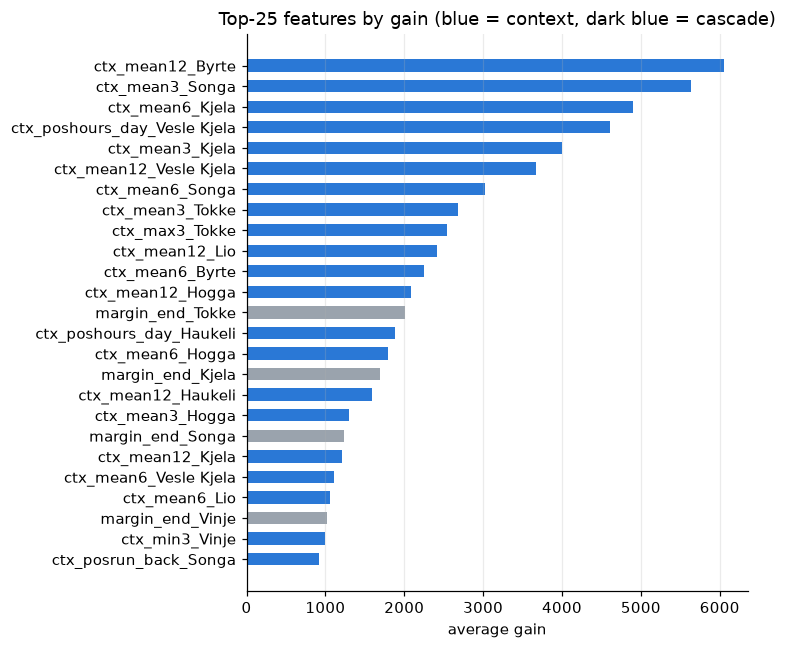

context            0.717
cascade            0.031
everything else    0.252
dtype: float64

In [6]:
imp = pd.Series(res["model"].get_booster().get_score(importance_type="gain")).sort_values()
top = imp.tail(25)
colors = [BLUE if c in ctx_cols else DARK if c in casc_cols else GREY for c in top.index]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=colors, height=0.6)
ax.set_xlabel("average gain"); ax.set_title("Top-25 features by gain (blue = context, dark blue = cascade)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
grp = pd.Series({"context": imp[imp.index.isin(ctx_cols)].sum(), "cascade": imp[imp.index.isin(casc_cols)].sum(),
                 "everything else": imp[~imp.index.isin(ctx_cols + casc_cols)].sum()})
(grp / grp.sum()).round(3)

## 3. Error near transitions: did the context features fix what the error analysis found?

In [7]:
# share of squared error within 2 h of a true ON/OFF transition, before (constraints model preds not stored -> margin model) and now
def transition_error_share(P, Yv):
    n = len(P) // H
    P3, Y3 = P.reshape(n, H, N_UNITS), Yv.reshape(n, H, N_UNITS)
    se = (P3 - Y3) ** 2
    near = np.zeros_like(Y3, dtype=bool)
    chg = np.diff(Y3, axis=1) != 0                       # (n, H-1, u): change between t and t+1
    for k in range(-2, 3):                               # hours within 2 of either side of a change
        lo, hi = max(0, k + 1), min(H, H + k)            # hour index t = change_idx + 1 + k
        near[:, lo:hi, :] |= chg[:, lo - (k + 1):hi - (k + 1), :]
    return se[near].sum() / se.sum(), near.mean(), se.mean()
Yv = Y[res["val_mask"]].astype(float)
P_margin = np.load("results/val_pred_2022_margin.npy").astype(float)
for name, P in [("margin model (error analysis)", P_margin), ("context + cascade", res["pred"].astype(float))]:
    s, h, b = transition_error_share(P, Yv)
    print(f"{name:32s} error share within 2 h of a transition {s:.2f} (hours {h:.2f}), Brier {b:.4f}")

margin model (error analysis)    error share within 2 h of a transition 0.33 (hours 0.12), Brier 0.0546
context + cascade                error share within 2 h of a transition 0.37 (hours 0.12), Brier 0.0528


## 4. Refit on all years and write the submission

In [8]:
t0 = time.time()
final_model = xgb.XGBClassifier(n_estimators=res["n_rounds"], tree_method="hist", device=DEVICE, random_state=SEED, **params).fit(X, Y)
print(f"refit on {len(uc)} cases with {res['n_rounds']} rounds in {time.time() - t0:.0f}s")
X_test = build_features(test_map["starttime"])
assert list(X_test.columns) == list(X.columns) and int(X_test.isna().sum().sum()) == 0
submission = to_wide(final_model.predict_proba(X_test), test_map["Run No"])
assert list(submission.columns) == list(sample.columns)
vals = submission[label_cols].to_numpy(); assert ((vals >= 0) & (vals <= 1)).all()
fname = f"submission_xgb_context_cv{res['report_auc']:.4f}.csv"
submission.to_csv(fname, index=False); print("saved", fname, submission.shape)
np.save("results/val_pred_2022_context.npy", res["pred"].astype(np.float32))

refit on 2922 cases with 269 rounds in 194s


saved submission_xgb_context_cv0.9805.csv (725, 2353)
